# EDA ก่อนสร้างแบบจำลอง — ตัวแปรไหนสัมพันธ์กับผลลัพธ์จริง

**คำถามของโน้ตบุ๊กนี้**: จากตัวแปรทั้งหมดที่มี ตัวไหน *มีสิทธิ์* เป็น feature และตัวไหน *สัมพันธ์กับผลลัพธ์จริง*
เมื่อวัดอย่างที่โครงสร้างข้อมูลบังคับ — ไม่ใช่วัดแบบรวมทุกเปเปอร์ซึ่งจะได้ความต่างระหว่างห้องแล็บมาแทน

**ข้อจำกัดที่กำหนดทุกอย่างในโน้ตบุ๊กนี้**: ความแปรปรวนระหว่างเปเปอร์มากกว่าภายในเปเปอร์ ~3.5–4 เท่า
ตัวแปรที่ไม่แปรค่า *ภายใน* เปเปอร์จึงแยกไม่ออกจาก "เปเปอร์ไหนเป็นคนทำ" ใต้ LeaveOneGroupOut(paper)
→ **ทุกความสัมพันธ์ในโน้ตบุ๊กนี้รายงาน 2 แบบคู่กันเสมอ**

| วิธีวัด | หมายถึงอะไร | ใช้ทำอะไร |
|---|---|---|
| **รวมทุกเปเปอร์ (naive)** | เอา 95 อุปกรณ์มากองรวมกันแล้ววัด | อ้างอิงเท่านั้น — ปนความต่างระหว่างแล็บเต็ม ๆ |
| **ภายในเปเปอร์ (within)** | วัดในแต่ละเปเปอร์ก่อน แล้วรวมผลระดับเปเปอร์ | **ตัวที่เชื่อได้** — ทุกอย่างนอกจากตัวแปรที่สนใจถูกตรึงแล้ว |

ช่องว่างระหว่างสองค่านี้คือขนาดของ confound ที่ paper ใส่เข้ามา

---

## สิ่งที่โน้ตบุ๊กนี้ทำ

| § | หัวข้อ |
|---|---|
| 1 | สร้างตัวแปรทุกชนิดจากทุกตาราง แล้วจัดประเภท (ไม่ใช่แค่ที่มีใน `target_table`) |
| 2 | คัดกรอง 3 ด่าน: ความครอบคลุม · แปรค่าภายในเปเปอร์ · ความหลากหลาย |
| 3 | ความสัมพันธ์ตัวแปร ↔ ผลลัพธ์ วัดให้ถูกชนิดของตัวแปร (ต่อเนื่อง / ทวิภาค / จัดกลุ่ม) |
| 4 | ตัวแปรซ้ำซ้อนกันเอง — กันใส่ของเดิมสองรอบ |
| 5 | โซ่กลไก: ตัวแปร → ตัวกลาง → ผลลัพธ์ |
| 6 | ความสัมพันธ์เชิงปริมาณ (dose–response) |
| 7 | โครงสร้างของข้อมูลที่หายไป |
| 8 | ชุดตัวแปรที่เสนอให้ใช้จริง พร้อมเหตุผลรายตัว |

In [1]:
from math import comb
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

ROOT = Path.cwd() if (Path.cwd() / "processed" / "prepared_v2").exists() else Path.cwd().parent
V2 = ROOT / "processed" / "prepared_v2"

tt = pd.read_csv(V2 / "target_table.csv")
layers = pd.read_csv(V2 / "layers.csv")
mats = pd.read_csv(V2 / "materials.csv")
proc = pd.read_csv(V2 / "process.csv")
tt["paper"] = tt["device_id"].str.rsplit("_Sample", n=1).str[0]
PAP = dict(zip(tt.device_id, tt.paper))

_have = {f.name for f in font_manager.fontManager.ttflist}
FONT = next((f for f in ["Leelawadee UI", "Sarabun", "Thonburi", "Tahoma", "DejaVu Sans"] if f in _have),
            "DejaVu Sans")
C1, C2, C3, C4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, MUTED, GRID, BASE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "font.family": [FONT, "DejaVu Sans"], "axes.unicode_minus": False,
    "figure.dpi": 110, "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": BASE, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlecolor": INK, "axes.titlesize": 11, "font.size": 9.5})


def spearman(x, y):
    """rho, n -- เขียนเองเพื่อไม่พึ่ง scipy และให้ผลตรงกับโน้ตบุ๊กอื่นในโปรเจกต์"""
    m = pd.notna(x) & pd.notna(y)
    if m.sum() < 3:
        return np.nan, int(m.sum())
    xr, yr = pd.Series(x)[m].rank(), pd.Series(y)[m].rank()
    if xr.nunique() < 2 or yr.nunique() < 2:
        return np.nan, int(m.sum())
    return float(np.corrcoef(xr, yr)[0, 1]), int(m.sum())


def sign_test(vals):
    """p สองด้านแบบ exact binomial -> (p, k_pos, n) · ทิ้งค่า 0 และ NaN"""
    v = [x for x in vals if pd.notna(x) and x != 0]
    n, k = len(v), sum(1 for x in v if x > 0)
    if n == 0:
        return np.nan, 0, 0
    pmf = [comb(n, i) * 0.5 ** n for i in range(n + 1)]
    return min(1.0, sum(q for q in pmf if q <= pmf[k] + 1e-12)), k, n


def short(s, n=26):
    s = str(s)
    return s if len(s) <= n else s[:n - 1] + "…"


print(f"อุปกรณ์ {len(tt)} · เปเปอร์ {tt.paper.nunique()} · ฟอนต์กราฟ {FONT}")

อุปกรณ์ 95 · เปเปอร์ 31 · ฟอนต์กราฟ Leelawadee UI


## 1. สร้างตัวแปรทุกชนิด — ไม่ใช่แค่ที่มีใน `target_table`

`target_table` ยุบข้อมูลไว้ระดับอุปกรณ์แล้ว แต่**ตัวแปรที่แปรค่าภายในเปเปอร์บางตัวยังฝังอยู่ในตารางอื่น**
โดยเฉพาะตัว HTL เอง ซึ่งเปเปอร์หลายฉบับแปร *ตัววัสดุ* ไม่ใช่แค่การเคลือบผิว

| ตัวแปรที่ดึงเพิ่ม | มาจาก | ชนิด | ทำไมสำคัญ |
|---|---|---|---|
| `htl_dope` | ชื่อวัสดุชั้น 2 (`Cu:NiOx`, `La:NiOx`, `Sm:NiOx`, `NiOx:TTTS`) | จัดกลุ่ม | การเจือสารในเนื้อ HTL — คนละกลไกกับการเคลือบผิว |
| `htl_route` | ชื่อวัสดุชั้น 2 (`NPs` / `sputtered` / `e-beam`) | จัดกลุ่ม | **วิธีผลิต HTL** — เป็น process knob ตัวเดียวที่แปรภายในเปเปอร์ได้จริง |
| `htl_mod_material` · `htl_mod_class` | วัสดุชั้น 3 | ข้อความ / จัดกลุ่ม | สารที่ใช้ดัดแปลงผิว |
| `htl_dose` | ปริมาณสารของชั้น 3 | ต่อเนื่อง | ความเข้มข้นที่ใช้ — ตัวเดียวที่ให้ dose–response |
| `htl_thick` | ความหนาชั้น 2 | ต่อเนื่อง | ความหนา HTL |

In [2]:
F = tt.set_index("device_id").copy()

# ---- ชั้น 2 (HTL): วัสดุบอกทั้งการเจือสารและวิธีผลิต ----
_l2 = layers[layers.layer_id == 2].groupby("device_id")["material"].first()
F["htl_material"] = _l2


def htl_dope(m):
    """สารที่เจือลงในเนื้อ NiOx -- อ่านจากรูปแบบ 'X:NiO...' หรือชื่อสารประกอบที่รู้จัก"""
    if not isinstance(m, str):
        return np.nan
    hit = re.match(r"\s*([A-Z][a-z]?)\s*:\s*NiO", m)
    if hit:
        return hit.group(1)
    if "TTTS" in m:
        return "TTTS"
    return "ไม่เจือ"


def htl_route(m):
    """วิธีขึ้นฟิล์ม HTL -- คนละกลไกกันจริง ๆ ระหว่างสารละลาย/อนุภาค กับการสปัตเตอร์"""
    if not isinstance(m, str):
        return np.nan
    s = m.lower()
    if "sputter" in s:
        return "สปัตเตอร์"
    if "ebe" in s or "e-beam" in s:
        return "ลำอิเล็กตรอน"
    if "np" in s or "nanoparticle" in s:
        return "อนุภาคนาโน"
    return "สารละลาย"


F["htl_dope"] = F["htl_material"].map(htl_dope)
F["htl_route"] = F["htl_material"].map(htl_route)

# ---- ชั้น 3 (เคลือบผิว HTL): สาร + ตระกูล + ปริมาณ ----
_l3 = (layers[layers.layer_id == 3].groupby("device_id")["material"]
       .apply(lambda s: " + ".join(sorted(s.dropna().unique()))).replace("", np.nan))
F["htl_mod_material"] = _l3
F["htl_mod"] = F["htl_mod_kind"].notna()


def mod_class(mat):
    if not isinstance(mat, str) or not mat:
        return "ไม่ดัดแปลง"
    m = mat.upper()
    if any(k in m for k in ("PACZ", "PADBC", "PADMAC", "SAM")):
        return "SAM (คาร์บาโซล)"
    if any(k in m for k in ("PF6", "CSI", "EMIMI", "KI", "NAI")):
        return "เกลือไอออน"
    if any(k in m for k in ("AL2O3", "TIO2", "SIO2", "MGO")):
        return "ออกไซด์"
    return "โมเลกุลอินทรีย์"


F["htl_mod_class"] = F["htl_mod_material"].map(mod_class)

_m3 = mats[mats.layer_id == 3].copy()
_m3["amt"] = pd.to_numeric(_m3.get("amount_parsed", _m3.get("amount")), errors="coerce")
F["htl_dose"] = _m3.dropna(subset=["amt"]).groupby("device_id")["amt"].max()

_th = layers.copy()
_th["thk"] = pd.to_numeric(_th.get("thickness_nm_parsed", _th.get("thickness_nm")), errors="coerce")
F["htl_thick"] = _th[_th.layer_id == 2].groupby("device_id")["thk"].first()

F = F.reset_index()

# ---- จัดประเภทตัวแปรทุกตัว ----
TARGET = ["voc", "jsc", "ff", "pce"]
MEDIATOR = ["vtfl", "trap_density", "rs", "rrec"]
STABILITY = ["retention_25c", "degradation_rate"]
FEATURES = {
    "ดัดแปลงผิว HTL": ["htl_mod", "htl_mod_class", "coat_htl", "n_coating_layers"],
    "ตัว HTL เอง": ["htl_dope", "htl_route", "htl_thick", "htl_dose"],
    "สถาปัตยกรรมอื่น": ["coat_psk", "psk_mod_kind", "coat_etl", "etl_family", "is_coated"],
    "สูตรเคมี": ["a_Cs", "a_FA", "x_Br"],
    "พารามิเตอร์เชิงตัวเลข": ["psk_spin_rpm", "psk_anneal_C", "psk_anneal_time_s", "psk_spin_last_s",
                              "psk_spin_total_s", "htl_anneal_C", "antisolvent_vol_uL",
                              "antisolvent_drop_frac_of_total"],
}
ALL_FEAT = [c for v in FEATURES.values() for c in v]


def kind_of(c):
    s = F[c]
    if s.dropna().isin([True, False, 0, 1]).all() and s.nunique(dropna=True) <= 2:
        return "ทวิภาค"
    return "ต่อเนื่อง" if pd.api.types.is_numeric_dtype(s) else "จัดกลุ่ม"


print(f"ตัวแปรที่จะพิจารณา {len(ALL_FEAT)} ตัว · ผลลัพธ์ {len(TARGET)} · ตัวกลาง {len(MEDIATOR)} · เสถียรภาพ {len(STABILITY)}")
display(F[["device_id", "htl_material", "htl_dope", "htl_route", "htl_mod_class", "htl_dose"]].head(6))

ตัวแปรที่จะพิจารณา 24 ตัว · ผลลัพธ์ 4 · ตัวกลาง 4 · เสถียรภาพ 2


,device_id,htl_material,htl_dope,htl_route,htl_mod_class,htl_dose
0,10.1002admi.202500231_Sample1,NiOx NPs,ไม่เจือ,อนุภาคนาโน,ไม่ดัดแปลง,NaN
1,10.1002admi.202500231_Sample2,NiOx NPs,ไม่เจือ,อนุภาคนาโน,เกลือไอออน,25.0
2,10.1002admi.202500231_Sample3,NiOx NPs,ไม่เจือ,อนุภาคนาโน,เกลือไอออน,25.0
3,10.1002admi.202500231_Sample4,NiOx NPs,ไม่เจือ,อนุภาคนาโน,เกลือไอออน,25.0
4,10.1007_s10854-017-8094-9_Sample1,NiOx NPs,ไม่เจือ,อนุภาคนาโน,ไม่ดัดแปลง,NaN
5,10.1007_s10854-017-8094-9_Sample2,NiOx NPs,ไม่เจือ,อนุภาคนาโน,ไม่ดัดแปลง,NaN


## 2. คัดกรอง 3 ด่าน — ใครมีสิทธิ์เป็นตัวแปรต้น

ตัวแปรจะใช้ได้ต้องผ่านครบทั้งสาม ตกด่านไหนก็จบ

| ด่าน | เกณฑ์ | ตกแล้วเป็นยังไง |
|---|---|---|
| **1 ความครอบคลุม** | มีค่าอย่างน้อย ~20 อุปกรณ์ | ตัวอย่างน้อยเกินกว่าจะประเมินได้ |
| **2 แปรค่าภายในเปเปอร์** | อย่างน้อย 2 เปเปอร์ที่ค่าไม่เท่ากันในตัวเอง | **ด่านชี้ขาด** — ถ้าไม่ผ่าน แยกไม่ออกจากตัวตนของเปเปอร์ |
| **3 ความหลากหลาย** | ค่าไม่ซ้ำกันหมด และไม่ใช่ระดับเดียวครอบเกือบทั้งชุด | ไม่มีข้อมูลให้เรียนรู้ |

ด่าน 2 คือหัวใจ: ใต้ LeaveOneGroupOut(paper) ตอน hold out เปเปอร์หนึ่งออก
ตัวแปรที่คงที่ทั้งเปเปอร์จะกลายเป็น "ป้ายชื่อเปเปอร์" ที่โมเดลจำได้ ไม่ใช่กลไกที่เรียนรู้ได้

ชนิด   n  ระดับ  \
กลุ่ม                 ตัวแปร                                                 
ดัดแปลงผิว HTL        htl_mod                            ทวิภาค  95      2   
                      htl_mod_class                    จัดกลุ่ม  95      5   
                      coat_htl                           ทวิภาค  95      2   
                      n_coating_layers                ต่อเนื่อง  95      4   
ตัว HTL เอง           htl_dope                         จัดกลุ่ม  95      5   
                      htl_route                        จัดกลุ่ม  95      4   
                      htl_thick                       ต่อเนื่อง  30     10   
                      htl_dose                        ต่อเนื่อง  49     17   
สถาปัตยกรรมอื่น       coat_psk                           ทวิภาค  95      2   
                      psk_mod_kind                     จัดกลุ่ม  95      1   
                      coat_etl                           ทวิภาค  95      2   
                      etl_family                       จัดกลุ่ม  95      4   
                      is_coated                          ทวิภาค  95      2   
สูตรเคมี              a_Cs                            ต่อเนื่อง  95     13   
                      a_FA                            ต่อเนื่อง  95     18   
                      x_Br                            ต่อเนื่อง  95     16   
พารามิเตอร์เชิงตัวเลข psk_spin_rpm                    ต่อเนื่อง  86      5   
                      psk_anneal_C                    ต่อเนื่อง  91      5   
                      psk_anneal_time_s               ต่อเนื่อง  91      7   
                      psk_spin_last_s                 ต่อเนื่อง  84      7   
                      psk_spin_total_s                ต่อเนื่อง  84      6   
                      htl_anneal_C                    ต่อเนื่อง  79     11   
                      antisolvent_vol_uL              ต่อเนื่อง  58      8   
                      antisolvent_drop_frac_of_total  ต่อเนื่อง  68     17   

                                                      เปเปอร์ที่แปร  \
กลุ่ม                 ตัวแปร                                          
ดัดแปลงผิว HTL        htl_mod                                    22   
                      htl_mod_class                              22   
                      coat_htl                                   21   
                      n_coating_layers                           21   
ตัว HTL เอง           htl_dope                                    4   
                      htl_route                                   6   
                      htl_thick                                   1   
                      htl_dose                                    5   
สถาปัตยกรรมอื่น       coat_psk                                    1   
                      psk_mod_kind                                1   
                      coat_etl                                    0   
                      etl_family                                  0   
                      is_coated                                   0   
สูตรเคมี              a_Cs                                        1   
                      a_FA                                        1   
                      x_Br                                        1   
พารามิเตอร์เชิงตัวเลข psk_spin_rpm                                0   
                      psk_anneal_C                                0   
                      psk_anneal_time_s                           0   
                      psk_spin_last_s                             0   
                      psk_spin_total_s                            0   
                      htl_anneal_C                                0   
                      antisolvent_vol_uL                          0   
                      antisolvent_drop_frac_of_total              0   

                                                     ระดับเด่นสุด  \
กลุ่ม                 ตัวแปร                                        
ดัดแปลงผิว HTL        htl_mod                

ใช้เป็นตัวแปรต้นได้ 7: ['htl_mod', 'htl_mod_class', 'coat_htl', 'n_coating_layers', 'htl_dope', 'htl_route', 'htl_dose']
ใช้เป็นตัวควบคุมเท่านั้น 16: ['htl_thick', 'coat_psk', 'coat_etl', 'etl_family', 'is_coated', 'a_Cs', 'a_FA', 'x_Br', 'psk_spin_rpm', 'psk_anneal_C', 'psk_anneal_time_s', 'psk_spin_last_s', 'psk_spin_total_s', 'htl_anneal_C', 'antisolvent_vol_uL', 'antisolvent_drop_frac_of_total']


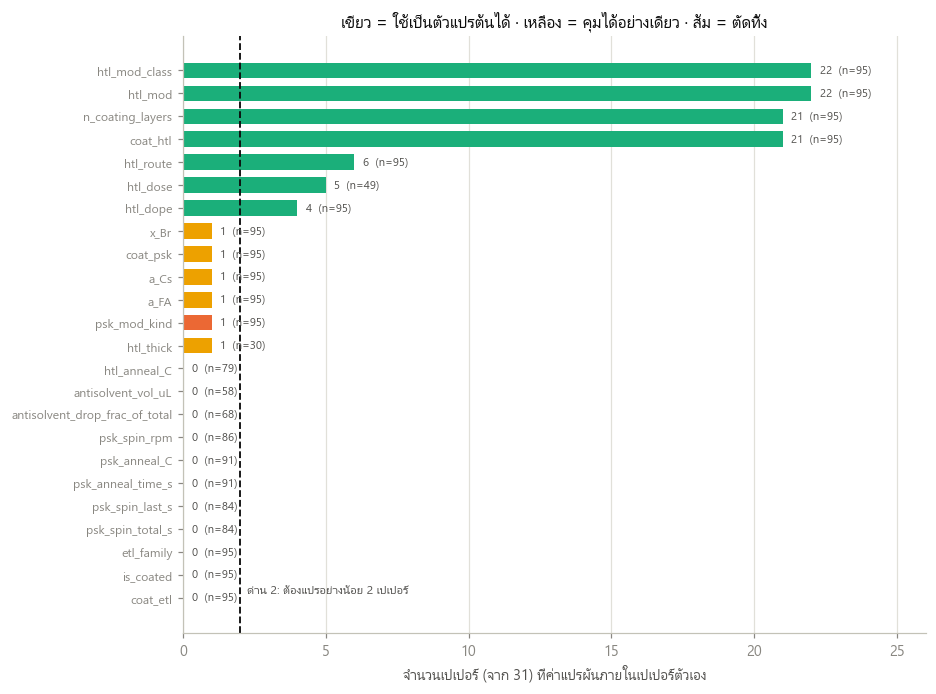

In [3]:
rows = []
for grp, cols in FEATURES.items():
    for c in cols:
        s = F[c]
        n = int(s.notna().sum())
        within = int((F.groupby("paper")[c].nunique(dropna=True) > 1).sum())
        # NaN ของ htl_mod_kind/psk_mod_kind แปลว่า "ไม่ดัดแปลง" ซึ่งเป็นระดับจริง ไม่ใช่ข้อมูลหาย
        if c in ("psk_mod_kind", "htl_mod_kind"):
            within = int((F.groupby("paper")[c].nunique(dropna=False) > 1).sum())
            n = len(F)
        top = s.value_counts(dropna=True)
        dom = float(top.iloc[0] / max(top.sum(), 1)) if len(top) else 1.0
        g1, g2, g3 = n >= 20, within >= 2, (s.nunique(dropna=True) >= 2 and dom <= 0.97)
        rows.append(dict(กลุ่ม=grp, ตัวแปร=c, ชนิด=kind_of(c), n=n,
                         ระดับ=int(s.nunique(dropna=True)), เปเปอร์ที่แปร=within,
                         ระดับเด่นสุด=f"{dom:.0%}",
                         ด่าน1=g1, ด่าน2=g2, ด่าน3=g3,
                         ผล="ใช้ได้" if (g1 and g2 and g3) else ("คุมได้ ใช้เป็นตัวต้นไม่ได้" if g1 and g3 else "ตัดทิ้ง")))
screen = pd.DataFrame(rows)
display(screen.set_index(["กลุ่ม", "ตัวแปร"])[["ชนิด", "n", "ระดับ", "เปเปอร์ที่แปร", "ระดับเด่นสุด", "ผล"]])

USABLE = screen.loc[screen.ผล == "ใช้ได้", "ตัวแปร"].tolist()
CONTROL = screen.loc[screen.ผล.str.startswith("คุมได้"), "ตัวแปร"].tolist()
print(f"ใช้เป็นตัวแปรต้นได้ {len(USABLE)}: {USABLE}")
print(f"ใช้เป็นตัวควบคุมเท่านั้น {len(CONTROL)}: {CONTROL}")

fig, ax = plt.subplots(figsize=(8.6, 6.4))
o = screen.sort_values("เปเปอร์ที่แปร")
col = {"ใช้ได้": C3, "คุมได้ ใช้เป็นตัวต้นไม่ได้": C4, "ตัดทิ้ง": C2}
ax.barh(range(len(o)), o["เปเปอร์ที่แปร"], color=[col[x] for x in o.ผล], height=0.68)
ax.axvline(2, color=INK, lw=1.2, ls="--")
ax.text(2.25, 0.2, "ด่าน 2: ต้องแปรอย่างน้อย 2 เปเปอร์", fontsize=8, color=INK2)
ax.set_yticks(range(len(o)), [short(x, 30) for x in o.ตัวแปร], fontsize=8)
for i, (v, n) in enumerate(zip(o["เปเปอร์ที่แปร"], o.n)):
    ax.text(v + 0.3, i, f"{v}  (n={n})", va="center", fontsize=7.4, color=INK2)
ax.set_xlim(0, 26); ax.grid(axis="y", visible=False)
ax.set_xlabel(f"จำนวนเปเปอร์ (จาก {F.paper.nunique()}) ที่ค่าแปรผันภายในเปเปอร์ตัวเอง")
ax.set_title("เขียว = ใช้เป็นตัวแปรต้นได้ · เหลือง = คุมได้อย่างเดียว · ส้ม = ตัดทิ้ง")
plt.tight_layout(); plt.show()

## 3. ความสัมพันธ์ตัวแปร ↔ ผลลัพธ์ — วัดให้ถูกชนิด

ใช้สถิติคนละตัวตามชนิดของตัวแปร และรายงานคู่กันทั้งแบบรวมและแบบภายในเปเปอร์เสมอ

| ชนิดตัวแปร | วัดยังไง (รวมทุกเปเปอร์) | วัดยังไง (ภายในเปเปอร์) |
|---|---|---|
| ต่อเนื่อง | สหสัมพันธ์อันดับ (Spearman) ทั้งชุด | คำนวณในแต่ละเปเปอร์แล้วเอาค่ากลาง |
| ทวิภาค / จัดกลุ่ม | ผลต่างค่ากลางระหว่างกลุ่ม | ผลต่างเทียบกับกลุ่มอ้างอิง**ในเปเปอร์เดียวกัน** แล้วรวมระดับเปเปอร์ |

หน่วยวิเคราะห์ของคอลัมน์ "ภายในเปเปอร์" คือ **เปเปอร์** ไม่ใช่อุปกรณ์ จึงไม่เกิดการนับตัวอย่างซ้ำ
และค่า p มาจาก sign test ซึ่งไม่ต้องสมมติการแจกแจง เหมาะกับ n เล็ก

In [4]:
def within_effect(feat, targ, min_dev=2):
    """ผลของตัวแปรต่อผลลัพธ์ วัดภายในเปเปอร์แล้วรวมระดับเปเปอร์
    ต่อเนื่อง -> Spearman รายเปเปอร์ · ทวิภาค/จัดกลุ่ม -> ผลต่างจากกลุ่มอ้างอิงในเปเปอร์นั้น
    คืน (ค่ากลางของผล, จำนวนเปเปอร์, สัดส่วนทิศทางเดียวกัน, p)"""
    k = kind_of(feat)
    per = []
    for _, g in F.groupby("paper"):
        g = g.dropna(subset=[targ])
        if len(g) < min_dev:
            continue
        if k == "ต่อเนื่อง":
            if g[feat].nunique(dropna=True) < 2 or len(g.dropna(subset=[feat])) < 3:
                continue
            r, _n = spearman(g[feat], g[targ])
            if pd.notna(r):
                per.append(r)
        else:
            x = g[feat].astype("object").where(g[feat].notna(), "—")
            if x.nunique() < 2:
                continue
            # กลุ่มอ้างอิง = ระดับที่แปลว่า "ไม่ทำอะไร" ถ้ามี ไม่งั้นใช้ระดับที่พบมากสุดในเปเปอร์นั้น
            ref = next((v for v in ["—", False, 0, "ไม่ดัดแปลง", "ไม่เจือ"] if (x == v).any()),
                       x.value_counts().index[0])
            base = g.loc[x == ref, targ].mean()
            other = g.loc[x != ref, targ].mean()
            if pd.notna(base) and pd.notna(other):
                per.append(other - base)
    if not per:
        return np.nan, 0, np.nan, np.nan
    p, kpos, n = sign_test(per)
    return float(np.median(per)), len(per), kpos / n if n else np.nan, p


def naive_effect(feat, targ):
    """วัดแบบกองรวมทุกเปเปอร์ -- ไว้เทียบให้เห็นขนาดของ confound"""
    if kind_of(feat) == "ต่อเนื่อง":
        r, _ = spearman(F[feat], F[targ])
        return r
    x = F[feat].astype("object").where(F[feat].notna(), "—")
    if x.nunique() < 2:
        return np.nan
    ref = next((v for v in ["—", False, 0, "ไม่ดัดแปลง", "ไม่เจือ"] if (x == v).any()),
               x.value_counts().index[0])
    return F.loc[x != ref, targ].mean() - F.loc[x == ref, targ].mean()


YCOLS = TARGET + MEDIATOR + STABILITY
res = []
for c in ALL_FEAT:
    for y in YCOLS:
        eff, npap, frac, pv = within_effect(c, y)
        res.append(dict(ตัวแปร=c, ผลลัพธ์=y, ชนิด=kind_of(c),
                        รวมทุกเปเปอร์=naive_effect(c, y),
                        ภายในเปเปอร์=eff, n_paper=npap, ทิศเดียวกัน=frac, p=pv))
R = pd.DataFrame(res)
print(f"คำนวณ {len(R)} คู่ (ตัวแปร x ผลลัพธ์)")
sig = R[(R.n_paper >= 3) & (R.p < 0.05)].sort_values("p")
print(f"คู่ที่วัดภายในเปเปอร์แล้วมีนัยสำคัญ (n_paper>=3, p<0.05): {len(sig)}")
display(sig.head(18).round(4).set_index(["ตัวแปร", "ผลลัพธ์"]))

คำนวณ 240 คู่ (ตัวแปร x ผลลัพธ์)
คู่ที่วัดภายในเปเปอร์แล้วมีนัยสำคัญ (n_paper>=3, p<0.05): 29


ชนิด  รวมทุกเปเปอร์  ภายในเปเปอร์  \
ตัวแปร           ผลลัพธ์                                                
htl_mod          pce              ทวิภาค   2.991200e+00  1.995000e+00   
htl_mod_class    pce            จัดกลุ่ม   2.991200e+00  1.995000e+00   
coat_htl         pce              ทวิภาค   3.223400e+00  2.090000e+00   
htl_mod          ff               ทวิภาค   3.556900e+00  1.961700e+00   
htl_mod_class    jsc            จัดกลุ่ม   1.505400e+00  6.217000e-01   
                 ff             จัดกลุ่ม   3.556900e+00  1.961700e+00   
htl_mod          jsc              ทวิภาค   1.505400e+00  6.217000e-01   
coat_htl         jsc              ทวิภาค   1.648600e+00  6.600000e-01   
                 ff               ทวิภาค   3.318500e+00  2.233300e+00   
                 vtfl             ทวิภาค  -1.955000e-01 -1.450000e-01   
htl_mod_class    vtfl           จัดกลุ่ม  -1.955000e-01 -1.450000e-01   
htl_mod          vtfl             ทวิภาค  -1.955000e-01 -1.450000e-01   
htl_mod_class    trap_density   จัดกลุ่ม  -7.884164e+15 -1.645000e+15   
htl_mod          trap_density     ทวิภาค  -7.884164e+15 -1.645000e+15   
coat_htl         trap_density     ทวิภาค  -7.884164e+15 -1.645000e+15   
                 voc              ทวิภาค   6.150000e-02  5.000000e-02   
n_coating_layers pce           ต่อเนื่อง   5.931000e-01  7.746000e-01   
                 jsc           ต่อเนื่อง   5.194000e-01  7.746000e-01   

                               n_paper  ทิศเดียวกัน       p  
ตัวแปร           ผลลัพธ์                                     
htl_mod          pce                22       0.9545  0.0000  
htl_mod_class    pce                22       0.9545  0.0000  
coat_htl         pce                21       0.9524  0.0000  
htl_mod          ff                 22       0.9091  0.0001  
htl_mod_class    jsc                22       0.9091  0.0001  
                 ff                 22       0.9091  0.0001  
htl_mod          jsc                22       0.9091  0.0001  
coat_htl         jsc                21       0.9048  0.0002  
                 ff                 21       0.9048  0.0002  
                 vtfl               13       0.0000  0.0002  
htl_mod_class    vtfl               13       0.0000  0.0002  
htl_mod          vtfl               13       0.0000  0.0002  
htl_mod_class    trap_density       12       0.0000  0.0005  
htl_mod          trap_density       12       0.0000  0.0005  
coat_htl         trap_density       12       0.0000  0.0005  
                 voc                21       0.8571  0.0015  
n_coating_layers pce                13       0.9231  0.0034  
                 jsc                13       0.9231  0.0034

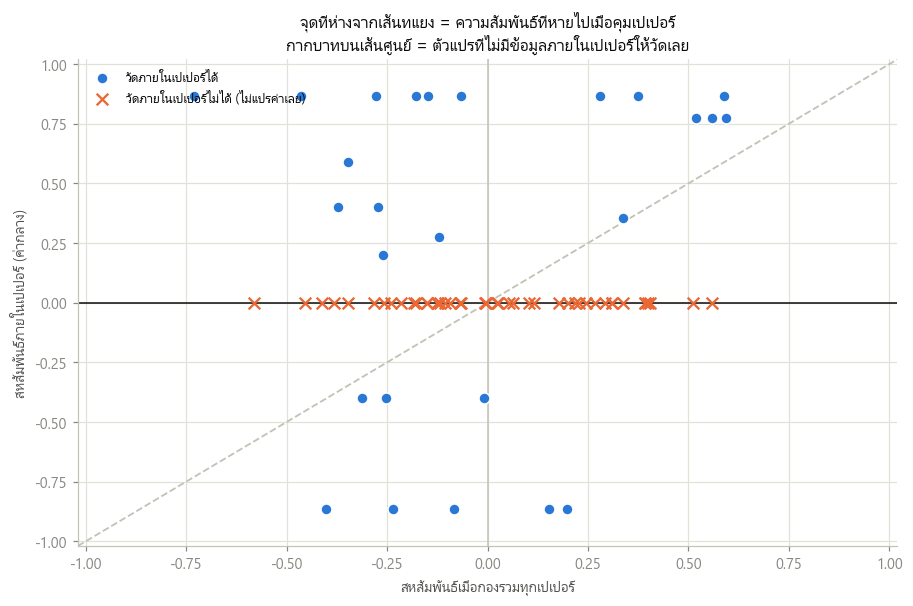

ตัวแปรต่อเนื่องที่วัดภายในเปเปอร์ไม่ได้เลย: 12 ตัว
  -> ['a_Cs', 'a_FA', 'antisolvent_drop_frac_of_total', 'antisolvent_vol_uL', 'htl_anneal_C', 'htl_thick', 'psk_anneal_C', 'psk_anneal_time_s', 'psk_spin_last_s', 'psk_spin_rpm', 'psk_spin_total_s', 'x_Br']

สหสัมพันธ์แรง ๆ ที่เห็นตอนกองรวม แต่หายไปเมื่อคุมเปเปอร์:


,,รวมทุกเปเปอร์
ตัวแปร,ผลลัพธ์,
x_Br,pce,-0.581
psk_spin_rpm,vtfl,0.558
a_FA,pce,0.511
psk_anneal_C,vtfl,-0.455
htl_anneal_C,voc,-0.411
psk_spin_last_s,pce,0.405


In [5]:
# เทียบ "รวมทุกเปเปอร์" กับ "ภายในเปเปอร์" -- ช่องว่างคือขนาดของ confound
sub = R[R.ตัวแปร.isin([c for c in ALL_FEAT if kind_of(c) == "ต่อเนื่อง"]) & R.ผลลัพธ์.isin(TARGET + ["vtfl"])]
sub = sub.dropna(subset=["รวมทุกเปเปอร์"])

fig, ax = plt.subplots(figsize=(8.4, 5.6))
_has = sub.dropna(subset=["ภายในเปเปอร์"])
_non = sub[sub["ภายในเปเปอร์"].isna()]
ax.scatter(_has["รวมทุกเปเปอร์"], _has["ภายในเปเปอร์"], s=52, color=C1,
           edgecolor="white", lw=1, zorder=3, label="วัดภายในเปเปอร์ได้")
ax.scatter(_non["รวมทุกเปเปอร์"], np.zeros(len(_non)), s=58, color=C2, marker="x",
           zorder=3, label="วัดภายในเปเปอร์ไม่ได้ (ไม่แปรค่าเลย)")
lim = 1.02
ax.plot([-lim, lim], [-lim, lim], color=BASE, lw=1.2, ls="--", zorder=1)
ax.axhline(0, color=INK, lw=1); ax.axvline(0, color=BASE, lw=1)
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel("สหสัมพันธ์เมื่อกองรวมทุกเปเปอร์"); ax.set_ylabel("สหสัมพันธ์ภายในเปเปอร์ (ค่ากลาง)")
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
ax.set_title("จุดที่ห่างจากเส้นทแยง = ความสัมพันธ์ที่หายไปเมื่อคุมเปเปอร์\nกากบาทบนเส้นศูนย์ = ตัวแปรที่ไม่มีข้อมูลภายในเปเปอร์ให้วัดเลย")
plt.tight_layout(); plt.show()

print(f"ตัวแปรต่อเนื่องที่วัดภายในเปเปอร์ไม่ได้เลย: {_non.ตัวแปร.nunique()} ตัว")
print("  ->", sorted(_non.ตัวแปร.unique()))
print()
print("สหสัมพันธ์แรง ๆ ที่เห็นตอนกองรวม แต่หายไปเมื่อคุมเปเปอร์:")
_g = _non.reindex(_non["รวมทุกเปเปอร์"].abs().sort_values(ascending=False).index).head(6)
display(_g[["ตัวแปร", "ผลลัพธ์", "รวมทุกเปเปอร์"]].round(3).set_index(["ตัวแปร", "ผลลัพธ์"]))

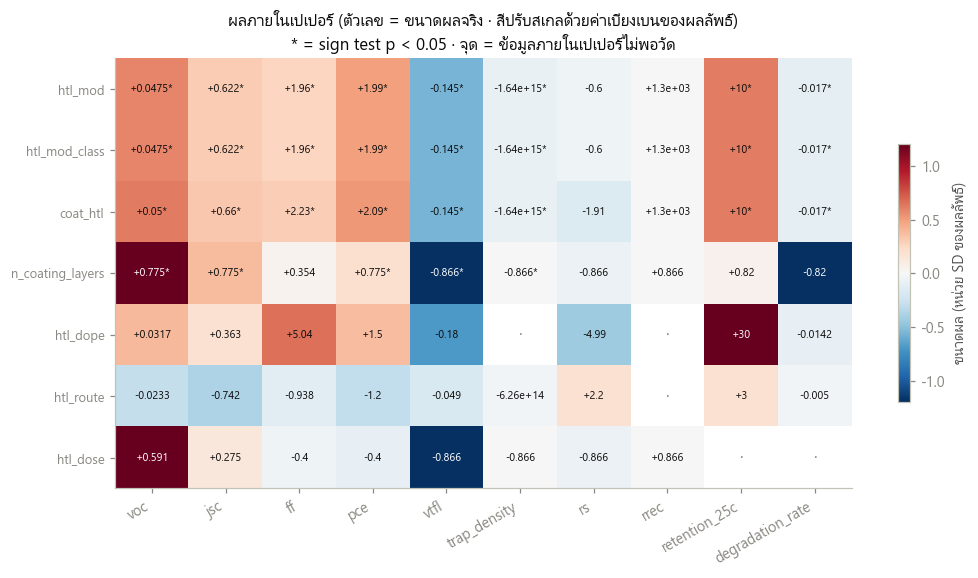

In [6]:
# แผนที่ความร้อน: เฉพาะตัวแปรที่วัดภายในเปเปอร์ได้จริง
ok_feat = sorted(R.loc[R.n_paper >= 3, "ตัวแปร"].unique(), key=lambda c: ALL_FEAT.index(c))
M = R[R.ตัวแปร.isin(ok_feat)].pivot(index="ตัวแปร", columns="ผลลัพธ์", values="ภายในเปเปอร์").reindex(ok_feat)[YCOLS]
N = R[R.ตัวแปร.isin(ok_feat)].pivot(index="ตัวแปร", columns="ผลลัพธ์", values="n_paper").reindex(ok_feat)[YCOLS]
P = R[R.ตัวแปร.isin(ok_feat)].pivot(index="ตัวแปร", columns="ผลลัพธ์", values="p").reindex(ok_feat)[YCOLS]

# ผลของแต่ละคอลัมน์คนละหน่วย -> ทำให้เทียบกันได้ด้วยการหารด้วยค่าเบี่ยงเบนของผลลัพธ์นั้น
Z = M.copy()
for y in YCOLS:
    sd = F[y].std()
    if pd.notna(sd) and sd > 0 and kind_of(ok_feat[0]) is not None:
        Z[y] = M[y] / sd
Z = Z.clip(-1.5, 1.5)

fig, ax = plt.subplots(figsize=(9.6, 0.42 * len(ok_feat) + 2.4))
im = ax.imshow(Z.values, cmap="RdBu_r", vmin=-1.2, vmax=1.2, aspect="auto")
ax.set_xticks(range(len(YCOLS)), YCOLS, rotation=30, ha="right")
ax.set_yticks(range(len(ok_feat)), ok_feat, fontsize=8.5)
for i in range(len(ok_feat)):
    for j, y in enumerate(YCOLS):
        v, n, pv = M.iloc[i, j], N.iloc[i, j], P.iloc[i, j]
        if pd.isna(v):
            ax.text(j, i, "·", ha="center", va="center", color=MUTED, fontsize=11)
            continue
        star = "*" if pd.notna(pv) and pv < 0.05 else ""
        ax.text(j, i, f"{v:+.3g}{star}", ha="center", va="center", fontsize=7,
                color="white" if abs(Z.iloc[i, j]) > 0.7 else INK)
ax.grid(False)
ax.set_title("ผลภายในเปเปอร์ (ตัวเลข = ขนาดผลจริง · สีปรับสเกลด้วยค่าเบี่ยงเบนของผลลัพธ์)\n"
             "* = sign test p < 0.05 · จุด = ข้อมูลภายในเปเปอร์ไม่พอวัด")
fig.colorbar(im, ax=ax, shrink=0.6, label="ขนาดผล (หน่วย SD ของผลลัพธ์)")
plt.tight_layout(); plt.show()

### 3.1 ตัวแปรจัดกลุ่ม — แยกผลรายระดับ

ตาราง §3 ยุบตัวจัดกลุ่มเป็น "ทำ vs ไม่ทำ" เพื่อให้เทียบกับตัวอื่นได้
แต่ข้อมูลที่มีค่ากว่าคือ **แต่ละระดับให้ผลต่างกันแค่ไหน** — ซึ่งเป็นสิ่งที่ตัวแปรทวิภาคบอกไม่ได้

เทียบแต่ละระดับกับกลุ่มอ้างอิง **ในเปเปอร์เดียวกัน** เท่านั้น
ระดับที่ไม่เคยอยู่ร่วมเปเปอร์กับกลุ่มอ้างอิงจะไม่มีแถว — ไม่ใช่ว่าไม่มีข้อมูล แต่ไม่มีคู่เทียบ

ผลลัพธ์  n_paper  ผลต่างจากกลุ่มอ้างอิง  \
ตัวแปร        ระดับ                                                     
htl_mod_class SAM (คาร์บาโซล)     pce        7                 4.0000   
htl_dope      TTTS                pce        1                 2.6900   
htl_mod_class โมเลกุลอินทรีย์     pce       14                 1.7950   
htl_dope      Cu                  pce        1                 1.5000   
              La                  pce        1                 1.5000   
              Sm                  pce        1                 0.8233   
htl_mod_class เกลือไอออน          pce        4                 0.5583   

                              ทิศเดียวกัน       p  
ตัวแปร        ระดับ                                
htl_mod_class SAM (คาร์บาโซล)         7/7  0.0156  
htl_dope      TTTS                    1/1  1.0000  
htl_mod_class โมเลกุลอินทรีย์       13/14  0.0018  
htl_dope      Cu                      1/1  1.0000  
              La                      1/1  1.0000  
              Sm                      1/1  1.0000  
htl_mod_class เกลือไอออน              3/4  0.6250

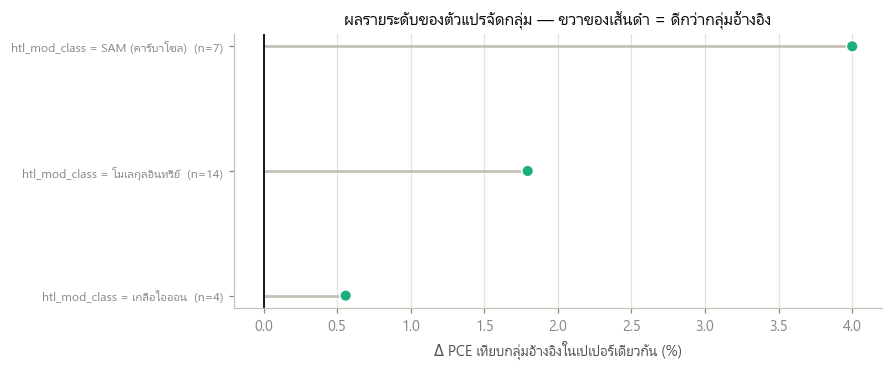


อ่านว่า: ระดับที่ n_paper น้อย (1-2) เป็นข้อสังเกต ไม่ใช่ผล -- ยังไม่พอสรุปว่าตัวไหนดีกว่าตัวไหน


In [7]:
CATS = [c for c in USABLE if kind_of(c) != "ต่อเนื่อง" and F[c].nunique(dropna=False) > 2]
rows = []
for c in CATS:
    for y in ["pce", "ff", "voc", "vtfl"]:
        per = {}
        for _, g in F.groupby("paper"):
            g = g.dropna(subset=[y])
            x = g[c].astype("object").where(g[c].notna(), "—")
            if x.nunique() < 2:
                continue
            ref = next((v for v in ["—", "ไม่ดัดแปลง", "ไม่เจือ", False, 0] if (x == v).any()), None)
            if ref is None:
                continue
            base = g.loc[x == ref, y].mean()
            for lv in x.unique():
                if lv == ref:
                    continue
                d = g.loc[x == lv, y].mean() - base
                if pd.notna(d):
                    per.setdefault(lv, []).append(d)
        for lv, vals in per.items():
            pv, k, n = sign_test(vals)
            rows.append(dict(ตัวแปร=c, ระดับ=str(lv), ผลลัพธ์=y, n_paper=len(vals),
                             ผลต่างจากกลุ่มอ้างอิง=round(float(np.median(vals)), 4),
                             ทิศเดียวกัน=f"{k}/{n}", p=round(pv, 4) if pd.notna(pv) else np.nan))
LV = pd.DataFrame(rows)
if len(LV):
    display(LV[LV.ผลลัพธ์ == "pce"].sort_values("ผลต่างจากกลุ่มอ้างอิง", ascending=False)
            .set_index(["ตัวแปร", "ระดับ"]))

    _pce = LV[(LV.ผลลัพธ์ == "pce") & (LV.n_paper >= 2)].sort_values("ผลต่างจากกลุ่มอ้างอิง")
    if len(_pce):
        fig, ax = plt.subplots(figsize=(8.2, 0.42 * len(_pce) + 2.2))
        y = np.arange(len(_pce))
        ax.hlines(y, 0, _pce["ผลต่างจากกลุ่มอ้างอิง"], color=BASE, lw=1.8, zorder=1)
        ax.scatter(_pce["ผลต่างจากกลุ่มอ้างอิง"], y, s=58,
                   color=[C3 if v > 0 else C2 for v in _pce["ผลต่างจากกลุ่มอ้างอิง"]],
                   edgecolor="white", lw=1, zorder=3)
        ax.axvline(0, color=INK, lw=1.2)
        ax.set_yticks(y, [f"{r.ตัวแปร} = {short(r.ระดับ, 22)}  (n={r.n_paper})" for r in _pce.itertuples()],
                      fontsize=8)
        ax.grid(axis="y", visible=False)
        ax.set_xlabel("Δ PCE เทียบกลุ่มอ้างอิงในเปเปอร์เดียวกัน (%)")
        ax.set_title("ผลรายระดับของตัวแปรจัดกลุ่ม — ขวาของเส้นดำ = ดีกว่ากลุ่มอ้างอิง")
        plt.tight_layout(); plt.show()
    print()
    print("อ่านว่า: ระดับที่ n_paper น้อย (1-2) เป็นข้อสังเกต ไม่ใช่ผล -- ยังไม่พอสรุปว่าตัวไหนดีกว่าตัวไหน")
else:
    print("ไม่มีตัวแปรจัดกลุ่มที่มีมากกว่า 2 ระดับและมีคู่เทียบในเปเปอร์เดียวกัน")

## 4. ตัวแปรซ้ำซ้อนกันเอง

ถ้าสองตัวแปรบอกเรื่องเดียวกัน การใส่ทั้งคู่จะทำให้น้ำหนักที่โมเดลให้ถูกแบ่งกันจนอ่านไม่ออก
(ปัญหาเดียวกับที่เอกสารเตือนไว้เรื่องจังหวะหยด antisolvent ที่มี 3 คอลัมน์บอกสิ่งเดียวกัน)

คู่ที่ซ้ำซ้อนกันสูง (|ค่า| >= 0.7) -- เลือกใส่แค่ตัวเดียวต่อคู่


ความซ้ำซ้อน           วิธีวัด   n
ตัวแปร_A         ตัวแปร_B                                           
htl_mod          coat_htl                  NaN         ทายกันได้  95
                 htl_dope                  NaN         ทายกันได้  95
                 coat_etl                  NaN         ทายกันได้  95
                 is_coated                 NaN         ทายกันได้  95
htl_mod_class    coat_htl                  NaN         ทายกันได้  95
                 htl_dope                  NaN         ทายกันได้  95
                 coat_etl                  NaN         ทายกันได้  95
                 is_coated                 NaN         ทายกันได้  95
coat_htl         htl_dope                  NaN         ทายกันได้  95
                 coat_etl                  NaN         ทายกันได้  95
                 is_coated                 NaN         ทายกันได้  95
n_coating_layers htl_dope                  NaN         ทายกันได้  95
                 coat_etl                  NaN         ทายกันได้  95
                 is_coated                 NaN         ทายกันได้  95
htl_dope         htl_thick                 NaN         ทายกันได้  95
                 coat_etl                  NaN         ทายกันได้  95
                 is_coated                 NaN         ทายกันได้  95
htl_route        coat_etl                  NaN         ทายกันได้  95
                 is_coated                 NaN         ทายกันได้  95
htl_dose         coat_etl                  NaN         ทายกันได้  95
                 is_coated                 NaN         ทายกันได้  95
htl_thick        coat_etl                  NaN         ทายกันได้  95
                 is_coated                 NaN         ทายกันได้  95
                 htl_anneal_C              NaN  สหสัมพันธ์อันดับ  16
coat_psk         coat_etl                  NaN         ทายกันได้  95
                 is_coated                 NaN         ทายกันได้  95
coat_etl         is_coated                 NaN         ทายกันได้  95
etl_family       is_coated                 NaN         ทายกันได้  95
                 psk_anneal_C              NaN         ทายกันได้  95
psk_spin_last_s  psk_spin_total_s          NaN  สหสัมพันธ์อันดับ  84

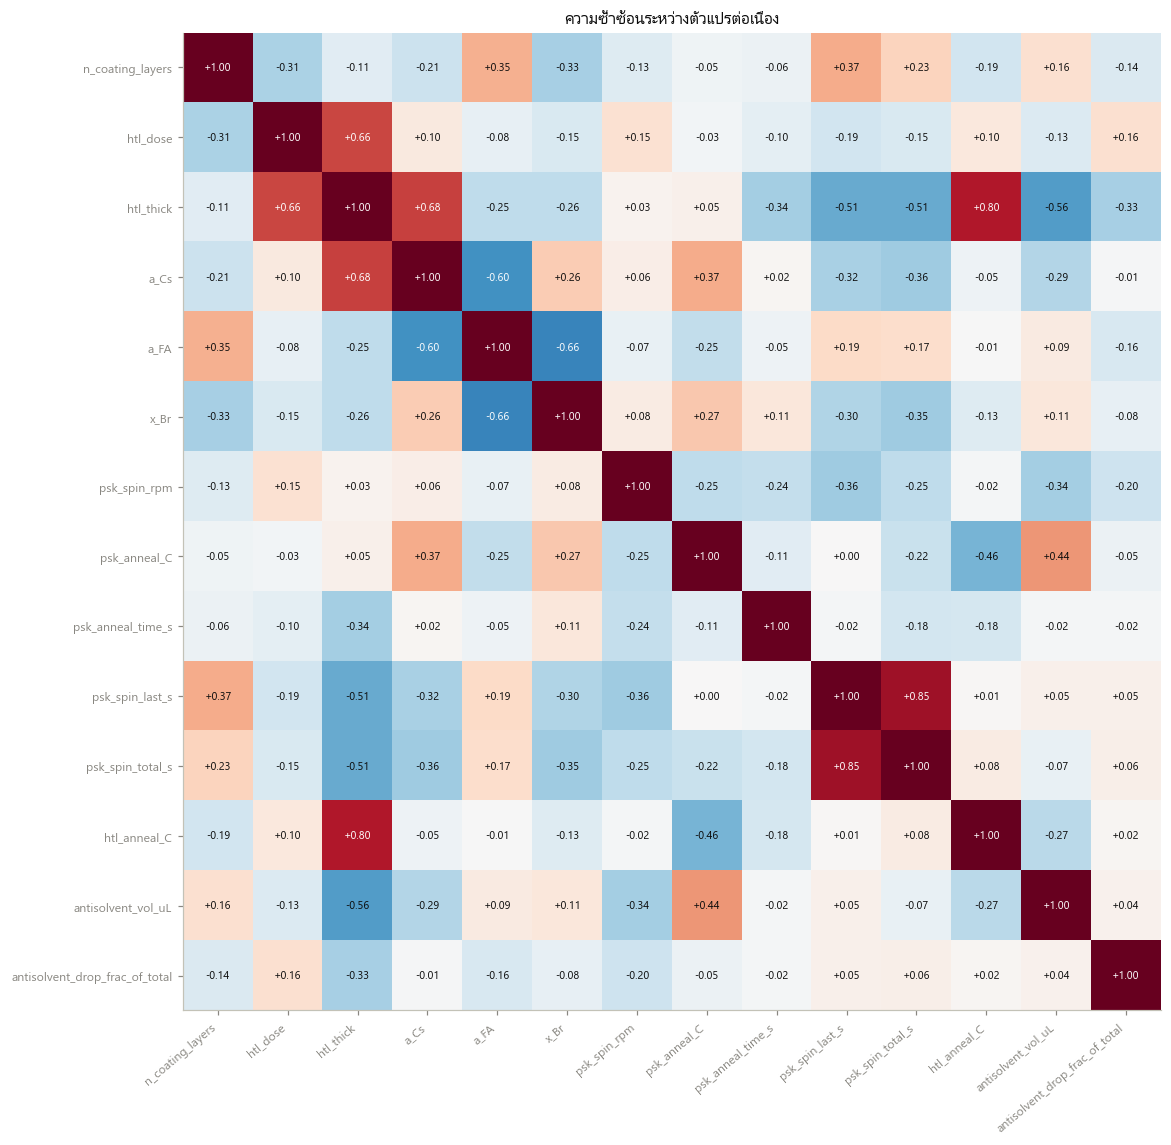

In [8]:
cand = [c for c in USABLE + CONTROL if F[c].notna().sum() >= 20]
num_cand = [c for c in cand if kind_of(c) == "ต่อเนื่อง"]
bin_cand = [c for c in cand if kind_of(c) != "ต่อเนื่อง"]

pairs = []
for i, a in enumerate(cand):
    for b in cand[i + 1:]:
        if kind_of(a) == "ต่อเนื่อง" and kind_of(b) == "ต่อเนื่อง":
            r, n = spearman(F[a], F[b])
            kind = "สหสัมพันธ์อันดับ"
        else:
            x = F[a].astype(str).fillna("—"); y = F[b].astype(str).fillna("—")
            m = x.notna() & y.notna()
            ct = pd.crosstab(x[m], y[m])
            # ความซ้ำซ้อนของตัวจัดกลุ่ม: ทายอีกตัวจากตัวนี้ได้แม่นแค่ไหน
            r = float(ct.max(axis=1).sum() / ct.values.sum()) if ct.values.sum() else np.nan
            r = (r - 1 / max(len(ct.columns), 1)) / (1 - 1 / max(len(ct.columns), 1)) if len(ct.columns) > 1 else np.nan
            n = int(m.sum()); kind = "ทายกันได้"
        if pd.notna(r) and abs(r) >= 0.7:
            pairs.append(dict(ตัวแปร_A=a, ตัวแปร_B=b, ความซ้ำซ้อน=round(float(r), 3), วิธีวัด=kind, n=n))
dup = pd.DataFrame(pairs, columns=["ตัวแปร_A", "ตัวแปร_B", "ความซ้ำซ้อน", "วิธีวัด", "n"])
if len(dup):
    dup = dup.sort_values("ความซ้ำซ้อน", key=abs, ascending=False)
    print("คู่ที่ซ้ำซ้อนกันสูง (|ค่า| >= 0.7) -- เลือกใส่แค่ตัวเดียวต่อคู่")
    display(dup.set_index(["ตัวแปร_A", "ตัวแปร_B"]))
else:
    print("ไม่พบคู่ที่ซ้ำซ้อนกันเกินเกณฑ์")

if len(num_cand) >= 2:
    Cm = pd.DataFrame({a: {b: spearman(F[a], F[b])[0] for b in num_cand} for a in num_cand})
    fig, ax = plt.subplots(figsize=(0.55 * len(num_cand) + 3.2, 0.55 * len(num_cand) + 2.8))
    im = ax.imshow(Cm.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(num_cand)), num_cand, rotation=40, ha="right", fontsize=8)
    ax.set_yticks(range(len(num_cand)), num_cand, fontsize=8)
    for i in range(len(num_cand)):
        for j in range(len(num_cand)):
            v = Cm.values[i, j]
            if pd.notna(v):
                ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=7,
                        color="white" if abs(v) > 0.6 else INK)
    ax.grid(False); ax.set_title("ความซ้ำซ้อนระหว่างตัวแปรต่อเนื่อง")
    plt.tight_layout(); plt.show()

## 5. โซ่กลไก — ตัวแปร → ตัวกลาง → ผลลัพธ์

สมมุติฐานของงาน: *ดัดแปลงผิว HTL → กับดักพาหะที่รอยต่อลดลง → FF/Voc ขึ้น → PCE ขึ้น*

โซ่จะน่าเชื่อก็ต่อเมื่อครบทั้งสามข้อต่อ **และวัดภายในเปเปอร์ทั้งหมด**
ถ้าข้อต่อกลางขาด แปลว่าผลที่เห็นอาจมาทางอื่น ไม่ใช่ทางที่เราคิด

ข้อ1_ตัวแปร_ตัวกลาง      p1  \
ตัวแปร           ตัวกลาง      ผลลัพธ์                                
htl_mod          vtfl         ff             -1.450000e-01  0.0002   
                              voc            -1.450000e-01  0.0002   
                              pce            -1.450000e-01  0.0002   
                 trap_density ff             -1.645000e+15  0.0005   
                              voc            -1.645000e+15  0.0005   
                              pce            -1.645000e+15  0.0005   
htl_mod_class    vtfl         ff             -1.450000e-01  0.0002   
                              voc            -1.450000e-01  0.0002   
                              pce            -1.450000e-01  0.0002   
                 trap_density ff             -1.645000e+15  0.0005   
                              voc            -1.645000e+15  0.0005   
                              pce            -1.645000e+15  0.0005   
coat_htl         vtfl         ff             -1.450000e-01  0.0002   
                              voc            -1.450000e-01  0.0002   
                              pce            -1.450000e-01  0.0002   
                 trap_density ff             -1.645000e+15  0.0005   
                              voc            -1.645000e+15  0.0005   
                              pce            -1.645000e+15  0.0005   
n_coating_layers vtfl         ff             -8.660000e-01  0.0312   
                              voc            -8.660000e-01  0.0312   
                              pce            -8.660000e-01  0.0312   
                 trap_density ff             -8.660000e-01  0.0312   
                              voc            -8.660000e-01  0.0312   
                              pce            -8.660000e-01  0.0312   

                                       ข้อ2_ตัวแปร_ผลลัพธ์      p2  \
ตัวแปร           ตัวกลาง      ผลลัพธ์                                
htl_mod          vtfl         ff                    1.9617  0.0001   
                              voc                   0.0475  0.0043   
                              pce                   1.9950  0.0000   
                 trap_density ff                    1.9617  0.0001   
                              voc                   0.0475  0.0043   
                              pce                   1.9950  0.0000   
htl_mod_class    vtfl         ff                    1.9617  0.0001   
                              voc                   0.0475  0.0043   
                              pce                   1.9950  0.0000   
                 trap_density ff                    1.9617  0.0001   
                              voc                   0.0475  0.0043   
                              pce                   1.9950  0.0000   
coat_htl         vtfl         ff                    2.2333  0.0002   
                              voc                   0.0500  0.0015   
                              pce                   2.0900  0.0000   
                 trap_density ff                    2.2333  0.0002   
                              voc                   0.0500  0.0015   
                              pce                   2.0900  0.0000   
n_coating_layers vtfl         ff                    0.3536  0.0654   
                              voc                   0.7746  0.0117   
                              pce                   0.7746  0.0034   
                 trap_density ff                    0.3536  0.0654   
                              voc                   0.7746  0.0117   
                              pce                   0.7746  0.0034   

                                       ข้อ3_ตัวกลาง_ผลลัพธ์  n3  
ตัวแปร           ตัวกลาง      ผลลัพธ์                            
htl_mod          vtfl         ff                      0.047  42  
                              voc                    -0.237  42  
                              pce                    -0.188  41  
                 trap_density ff                      0.051  35  
 

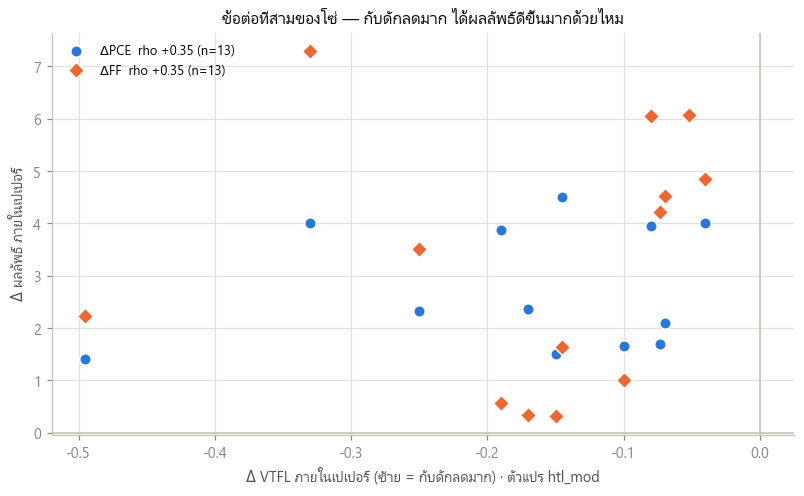

In [9]:
CHAIN_FEATS = [c for c in USABLE if F[c].notna().sum() >= 20][:4]
rows = []
for c in CHAIN_FEATS:
    for med in ["vtfl", "trap_density"]:
        e1, n1, _, p1 = within_effect(c, med)
        for y in ["ff", "voc", "pce"]:
            e2, n2, _, p2 = within_effect(c, y)
            rm, nm = spearman(F[med], F[y])
            rows.append(dict(ตัวแปร=c, ตัวกลาง=med, ผลลัพธ์=y,
                             ข้อ1_ตัวแปร_ตัวกลาง=round(e1, 4) if pd.notna(e1) else np.nan, p1=round(p1, 4) if pd.notna(p1) else np.nan,
                             ข้อ2_ตัวแปร_ผลลัพธ์=round(e2, 4) if pd.notna(e2) else np.nan, p2=round(p2, 4) if pd.notna(p2) else np.nan,
                             ข้อ3_ตัวกลาง_ผลลัพธ์=round(rm, 3) if pd.notna(rm) else np.nan, n3=nm))
chain = pd.DataFrame(rows)
display(chain.set_index(["ตัวแปร", "ตัวกลาง", "ผลลัพธ์"]))

# ภาพ: เปเปอร์ที่กับดักลดมาก ได้ผลลัพธ์ดีขึ้นมากด้วยไหม
main = CHAIN_FEATS[0] if CHAIN_FEATS else None
if main:
    per = []
    for p, g in F.groupby("paper"):
        x = g[main].astype("object").where(g[main].notna(), "—")
        if x.nunique() < 2:
            continue
        ref = next((v for v in ["—", False, 0, "ไม่ดัดแปลง", "ไม่เจือ"] if (x == v).any()), x.value_counts().index[0])
        rec = {"paper": p}
        for y in ["vtfl", "pce", "ff"]:
            b, o = g.loc[x == ref, y].mean(), g.loc[x != ref, y].mean()
            rec[y] = o - b if pd.notna(b) and pd.notna(o) else np.nan
        per.append(rec)
    D = pd.DataFrame(per).dropna(subset=["vtfl"])
    if len(D) >= 3:
        fig, ax = plt.subplots(figsize=(7.4, 4.6))
        for y, c, mk in [("pce", C1, "o"), ("ff", C2, "D")]:
            d2 = D.dropna(subset=[y])
            r, n = spearman(d2["vtfl"], d2[y])
            ax.scatter(d2["vtfl"], d2[y], s=56, color=c, marker=mk, edgecolor="white", lw=1,
                       label=f"Δ{y.upper()}  rho {r:+.2f} (n={n})")
        ax.axvline(0, color=BASE, lw=1); ax.axhline(0, color=BASE, lw=1)
        ax.set_xlabel(f"Δ VTFL ภายในเปเปอร์ (ซ้าย = กับดักลดมาก) · ตัวแปร {main}")
        ax.set_ylabel("Δ ผลลัพธ์ ภายในเปเปอร์")
        ax.legend(frameon=False, fontsize=8.5)
        ax.set_title("ข้อต่อที่สามของโซ่ — กับดักลดมาก ได้ผลลัพธ์ดีขึ้นมากด้วยไหม")
        plt.tight_layout(); plt.show()

## 6. ความสัมพันธ์เชิงปริมาณ (dose–response)

ตัวแปรทวิภาคบอกได้แค่ "ทำหรือไม่ทำ" · เปเปอร์ที่ไล่ปริมาณจะบอกได้ว่า **มีจุดเหมาะสมไหม**
ซึ่งเป็นข้อมูลที่ใช้ตอบคำถาม "ดัดแปลงมากขึ้นดีขึ้นเสมอหรือเปล่า" ได้โดยตรง

เปเปอร์ที่ไล่ปริมาณสารดัดแปลง: 5


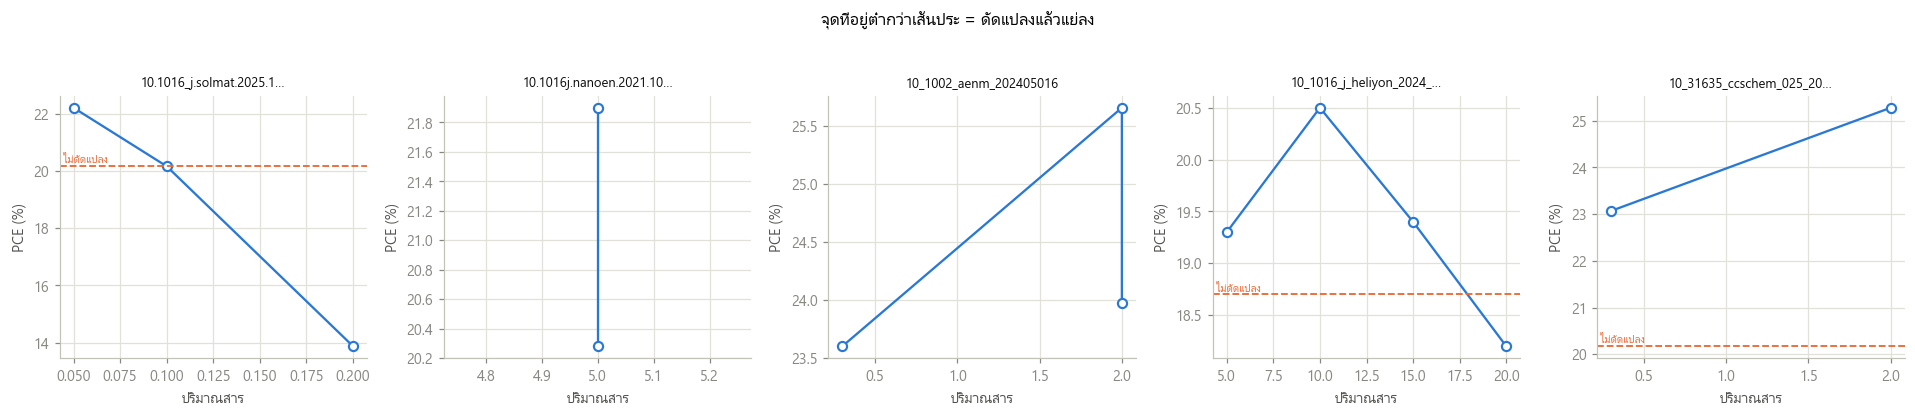

  10.1016_j.solmat.2025.113858         ดีสุดที่ปริมาณ 0.05 (PCE 22.22) · rho -1.00 -> ลงตลอด
  10_1002_aenm_202405016               ดีสุดที่ปริมาณ 2 (PCE 25.66) · rho +0.87 -> มีจุดเหมาะสม (ไม่ใช่ยิ่งมากยิ่งดี)
  10_1016_j_heliyon_2024_e25352        ดีสุดที่ปริมาณ 10 (PCE 20.50) · rho -0.40 -> มีจุดเหมาะสม (ไม่ใช่ยิ่งมากยิ่งดี)


In [10]:
dose_papers = [p for p, g in F.groupby("paper") if g["htl_dose"].nunique(dropna=True) > 1]
print(f"เปเปอร์ที่ไล่ปริมาณสารดัดแปลง: {len(dose_papers)}")
if dose_papers:
    fig, axes = plt.subplots(1, len(dose_papers), figsize=(3.5 * len(dose_papers), 3.6), squeeze=False)
    for ax, p in zip(axes[0], dose_papers):
        g = F[F.paper == p].sort_values("htl_dose")
        ctrl = g.loc[~g.htl_mod, "pce"].mean()
        ax.plot(g["htl_dose"], g["pce"], "-o", color=C1, ms=6, markerfacecolor="white", mew=1.4)
        if pd.notna(ctrl):
            ax.axhline(ctrl, color=C2, ls="--", lw=1.2)
            ax.text(ax.get_xlim()[0], ctrl, " ไม่ดัดแปลง", fontsize=7.2, color=C2, va="bottom")
        ax.set_title(short(p, 24), fontsize=8.5)
        ax.set_xlabel("ปริมาณสาร"); ax.set_ylabel("PCE (%)")
    fig.suptitle("จุดที่อยู่ต่ำกว่าเส้นประ = ดัดแปลงแล้วแย่ลง", y=1.04)
    plt.tight_layout(); plt.show()

    for p in dose_papers:
        g = F[F.paper == p].dropna(subset=["htl_dose", "pce"]).sort_values("htl_dose")
        if len(g) >= 3:
            best = g.loc[g.pce.idxmax()]
            r, n = spearman(g.htl_dose, g.pce)
            mono = "ขึ้นตลอด" if r > 0.9 else ("ลงตลอด" if r < -0.9 else "มีจุดเหมาะสม (ไม่ใช่ยิ่งมากยิ่งดี)")
            print(f"  {short(p, 34):36s} ดีสุดที่ปริมาณ {best.htl_dose:g} (PCE {best.pce:.2f}) · rho {r:+.2f} -> {mono}")

## 7. โครงสร้างของข้อมูลที่หายไป

ค่าที่หายไปในชุดนี้**หายเป็นก้อนตามเปเปอร์** ไม่ได้หายแบบสุ่ม — เปเปอร์ที่ไม่วัด SCLC ก็ไม่มีทั้งฉบับ
ผลคือ **ห้ามเติมค่าข้ามเปเปอร์เด็ดขาด** เพราะเท่ากับประดิษฐ์ข้อมูลของแล็บหนึ่งจากอีกแล็บหนึ่ง
และเวลาเลือกชุดตัวแปร ต้องรู้ว่าการเพิ่มตัวแปรที่ครอบคลุมน้อยจะตัดอุปกรณ์ทิ้งไปเท่าไหร่

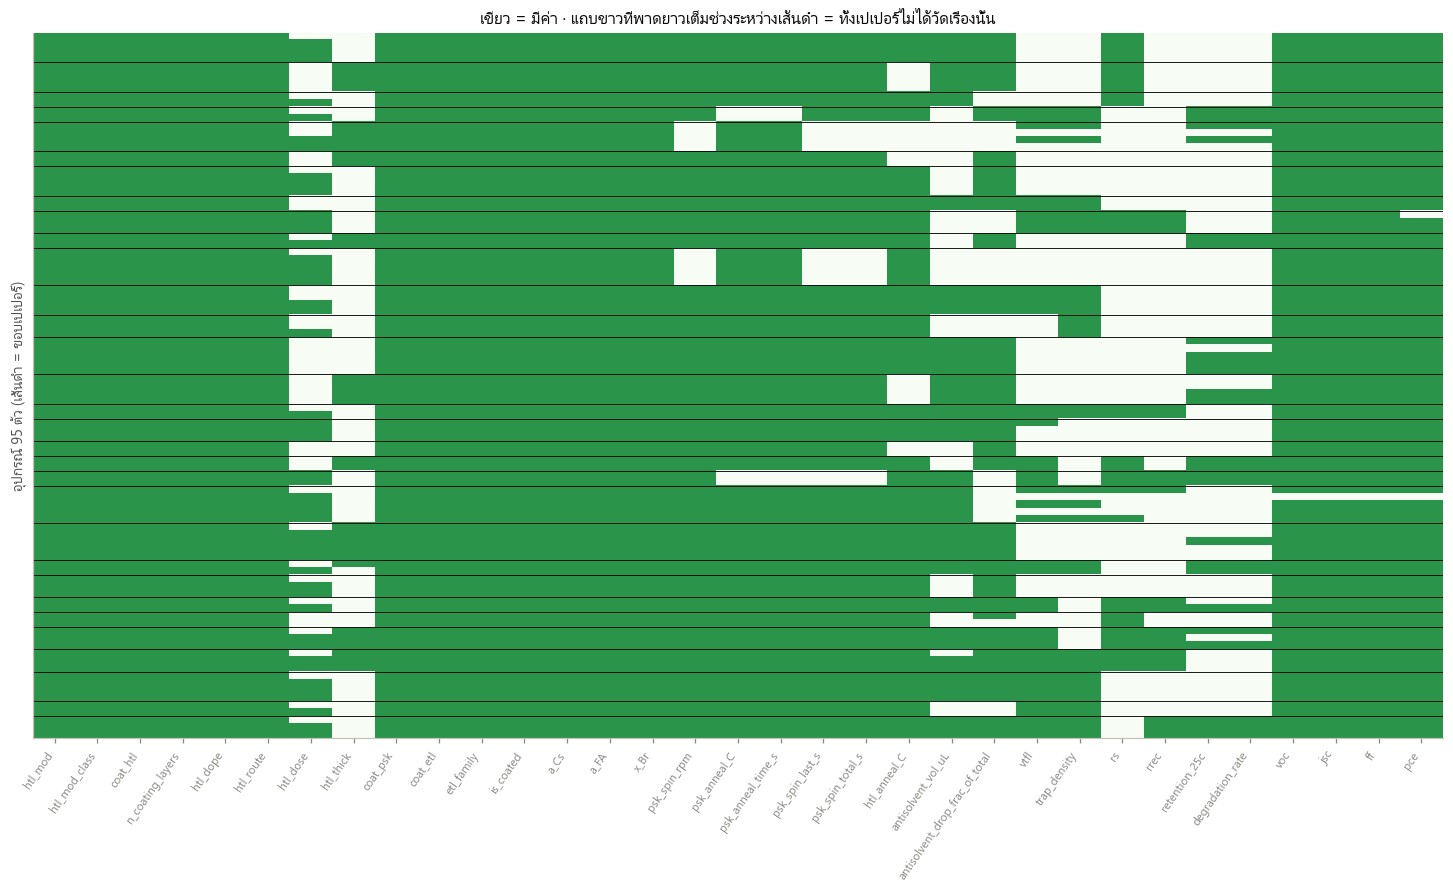

,อุปกรณ์ที่มีค่า,เปเปอร์ที่วัดเรื่องนี้,หายทั้งเปเปอร์
ตัวแปร,,,
rrec,19,8,74%
retention_25c,25,12,61%
degradation_rate,25,12,61%
htl_thick,30,10,68%
rs,31,12,61%
trap_density,35,13,58%
vtfl,42,17,45%
htl_dose,49,23,26%
antisolvent_vol_uL,58,18,42%


อ่านว่า: คอลัมน์ 'หายทั้งเปเปอร์' สูง = ข้อมูลหายเป็นก้อน (MNAR) ไม่ใช่หายแบบสุ่ม


In [11]:
show = [c for c in USABLE + CONTROL if F[c].notna().sum() >= 5] + MEDIATOR + STABILITY + TARGET
show = list(dict.fromkeys(show))
Mx = F.sort_values(["paper", "device_id"])[show].notna().astype(int)

fig, ax = plt.subplots(figsize=(0.30 * len(show) + 3.4, 8.2))
ax.imshow(Mx.values, cmap="Greens", aspect="auto", vmin=0, vmax=1.4)
ax.set_xticks(range(len(show)), show, rotation=55, ha="right", fontsize=7.6)
_pap = F.sort_values(["paper", "device_id"]).paper.values
_edges = [i for i in range(1, len(_pap)) if _pap[i] != _pap[i - 1]]
for e in _edges:
    ax.axhline(e - 0.5, color=INK, lw=0.6)
ax.set_yticks([]); ax.grid(False)
ax.set_ylabel(f"อุปกรณ์ {len(F)} ตัว (เส้นดำ = ขอบเปเปอร์)")
ax.set_title("เขียว = มีค่า · แถบขาวที่พาดยาวเต็มช่วงระหว่างเส้นดำ = ทั้งเปเปอร์ไม่ได้วัดเรื่องนั้น")
plt.tight_layout(); plt.show()

pap_lvl = F.groupby("paper")[show].apply(lambda g: g.notna().any())
rows = [dict(ตัวแปร=c, อุปกรณ์ที่มีค่า=int(F[c].notna().sum()),
             เปเปอร์ที่วัดเรื่องนี้=int(pap_lvl[c].sum()),
             หายทั้งเปเปอร์=f"{1 - pap_lvl[c].mean():.0%}") for c in show]
mi = pd.DataFrame(rows).sort_values("อุปกรณ์ที่มีค่า")
display(mi.set_index("ตัวแปร"))
print("อ่านว่า: คอลัมน์ 'หายทั้งเปเปอร์' สูง = ข้อมูลหายเป็นก้อน (MNAR) ไม่ใช่หายแบบสุ่ม")

## 8. ชุดตัวแปรที่เสนอให้ใช้ — พร้อมเหตุผลรายตัว

In [12]:
def why(c):
    row = screen.set_index("ตัวแปร").loc[c]
    best = R[(R.ตัวแปร == c) & (R.n_paper >= 3)].dropna(subset=["p"]).sort_values("p")
    if len(best):
        b = best.iloc[0]
        ev = f"แรงสุดกับ {b.ผลลัพธ์} (ผล {b['ภายในเปเปอร์']:+.3g} · {int(b.n_paper)} เปเปอร์ · p={b.p:.3g})"
    else:
        ev = "ยังไม่มีคู่ที่วัดภายในเปเปอร์ได้พอ"
    return row.ชนิด, int(row.n), int(row["เปเปอร์ที่แปร"]), ev


plan = []
for c in USABLE:
    k, n, w, ev = why(c)
    plan.append(dict(บทบาท="ตัวแปรต้น", ตัวแปร=c, ชนิด=k, n=n, เปเปอร์ที่แปร=w, หลักฐาน=ev))
for c in CONTROL:
    k, n, w, ev = why(c)
    plan.append(dict(บทบาท="ตัวควบคุม", ตัวแปร=c, ชนิด=k, n=n, เปเปอร์ที่แปร=w,
                     หลักฐาน="คุมไว้เพราะกระทบผลลัพธ์ทางฟิสิกส์ แต่ไม่แปรภายในเปเปอร์ จึงตีความน้ำหนักไม่ได้"))
PLAN = pd.DataFrame(plan)
display(PLAN.set_index(["บทบาท", "ตัวแปร"]))

AUD = ROOT / "processed" / "audit"
AUD.mkdir(parents=True, exist_ok=True)
screen.to_csv(AUD / "eda_feature_screen.csv", index=False, encoding="utf-8-sig")
R.to_csv(AUD / "eda_feature_target_effects.csv", index=False, encoding="utf-8-sig")
PLAN.to_csv(AUD / "eda_feature_plan.csv", index=False, encoding="utf-8-sig")
print("เขียนไฟล์สรุป:")
for f in ["eda_feature_screen.csv", "eda_feature_target_effects.csv", "eda_feature_plan.csv"]:
    print("  processed/audit/" + f)

print()
print(f"ตัวแปรต้นที่ใช้ได้ {len(USABLE)} ตัว · ตัวควบคุม {len(CONTROL)} ตัว")
print(f"อุปกรณ์ที่มีตัวแปรต้นครบทุกตัว: {int(F[USABLE].notna().all(axis=1).sum())} / {len(F)}")
_n_ok = int(F.dropna(subset=USABLE + ['pce']).paper.nunique())
print(f"เปเปอร์ที่ใช้ได้เมื่อบังคับให้มีครบ: {_n_ok} / {F.paper.nunique()}")

ชนิด   n  เปเปอร์ที่แปร  \
บทบาท     ตัวแปร                                                         
ตัวแปรต้น htl_mod                            ทวิภาค  95             22   
          htl_mod_class                    จัดกลุ่ม  95             22   
          coat_htl                           ทวิภาค  95             21   
          n_coating_layers                ต่อเนื่อง  95             21   
          htl_dope                         จัดกลุ่ม  95              4   
          htl_route                        จัดกลุ่ม  95              6   
          htl_dose                        ต่อเนื่อง  49              5   
ตัวควบคุม htl_thick                       ต่อเนื่อง  30              1   
          coat_psk                           ทวิภาค  95              1   
          coat_etl                           ทวิภาค  95              0   
          etl_family                       จัดกลุ่ม  95              0   
          is_coated                          ทวิภาค  95              0   
          a_Cs                            ต่อเนื่อง  95              1   
          a_FA                            ต่อเนื่อง  95              1   
          x_Br                            ต่อเนื่อง  95              1   
          psk_spin_rpm                    ต่อเนื่อง  86              0   
          psk_anneal_C                    ต่อเนื่อง  91              0   
          psk_anneal_time_s               ต่อเนื่อง  91              0   
          psk_spin_last_s                 ต่อเนื่อง  84              0   
          psk_spin_total_s                ต่อเนื่อง  84              0   
          htl_anneal_C                    ต่อเนื่อง  79              0   
          antisolvent_vol_uL              ต่อเนื่อง  58              0   
          antisolvent_drop_frac_of_total  ต่อเนื่อง  68              0   

                                                                                    หลักฐาน  
บทบาท     ตัวแปร                                                                             
ตัวแปรต้น htl_mod                         แรงสุดกับ pce (ผล +1.99 · 22 เปเปอร์ · p=1.1e-05)  
          htl_mod_class                   แรงสุดกับ pce (ผล +1.99 · 22 เปเปอร์ · p=1.1e-05)  
          coat_htl                        แรงสุดกับ pce (ผล +2.09 · 21 เปเปอร์ · p=2.1e-05)  
          n_coating_layers                แรงสุดกับ jsc (ผล +0.775 · 13 เปเปอร์ · p=0.00...  
          htl_dope                         แรงสุดกับ voc (ผล +0.0317 · 4 เปเปอร์ · p=0.125)  
          htl_route                           แรงสุดกับ pce (ผล -1.2 · 6 เปเปอร์ · p=0.219)  
          htl_dose                          แรงสุดกับ voc (ผล +0.591 · 4 เปเปอร์ · p=0.625)  
ตัวควบคุม htl_thick                       คุมไว้เพราะกระทบผลลัพธ์ทางฟิสิกส์ แต่ไม่แปรภาย...  
          coat_psk                        คุมไว้เพราะกระทบผลลัพธ์ทางฟิสิกส์ แต่ไม่แปรภาย...  
          coat_etl                        คุมไว้เพราะกระทบผลลัพธ์ทางฟิสิกส์ แต่ไม่แปรภาย...  
          etl_family                      คุมไว้เพราะกระทบผลลัพธ์ทางฟิสิกส์ แต่ไม่แปรภาย...  
          is_coated                       คุมไว้เพราะกระทบผลลัพธ์ทางฟิสิกส์ แต่ไม่แปรภาย...  
          a_Cs                            คุมไว้เพราะกระทบผลลัพธ์ทางฟิสิกส์ แต่ไม่แปรภาย...  
          a_FA                            คุมไว้เพราะกระทบผลลัพธ์ทางฟิสิกส์ แต่ไม่แปรภาย...  
          x_Br                            คุมไว้เพราะกระทบผลลัพธ์ทางฟิสิกส์ แต่ไม่แปรภาย...  
          psk_spin_rpm                    คุมไว้เพราะกระทบผลลัพธ์ทางฟิสิกส์ แต่ไม่แปรภาย...  
          psk_anneal_C                    คุมไว้เพราะกระทบผลลัพธ์ทางฟิสิกส์ แต่ไม่แปรภาย...  
          psk_anneal_time_s               คุมไว้เพราะกระทบผลลัพธ์ทางฟิสิกส์ แต่ไม่แปรภาย...  
          psk_spin_last_s                 คุมไว้เพราะกระทบผลลัพธ์ทางฟิสิกส์ แต่ไม่แปรภาย...  
          psk_spin_total_s                คุมไว้เพราะกระทบผลลัพธ์ทางฟิสิกส์ แต่ไม่แปรภาย...  
          htl_anneal_C                    คุมไว้เพราะกระทบผลลัพธ์ทางฟิสิกส์ แต่ไม่แปรภาย...  
          antisolvent_vol_uL      

เขียนไฟล์สรุป:
  processed/audit/eda_feature_screen.csv
  processed/audit/eda_feature_target_effects.csv
  processed/audit/eda_feature_plan.csv

ตัวแปรต้นที่ใช้ได้ 7 ตัว · ตัวควบคุม 16 ตัว
อุปกรณ์ที่มีตัวแปรต้นครบทุกตัว: 49 / 95
เปเปอร์ที่ใช้ได้เมื่อบังคับให้มีครบ: 23 / 31


## สรุป — อ่านอะไรจากโน้ตบุ๊กนี้ได้บ้าง

1. **ตัวแปรส่วนใหญ่ใช้เป็นตัวแปรต้นไม่ได้** (§2) — ไม่ใช่เพราะข้อมูลไม่ครบ แต่เพราะไม่แปรค่าภายในเปเปอร์
   พารามิเตอร์เชิงตัวเลขทุกตัว (ความเร็วปั่น อุณหภูมิและเวลาอบ จังหวะ antisolvent) ตกด่านนี้ทั้งหมด

2. **ความสัมพันธ์แรง ๆ ที่เห็นตอนกองรวมทุกเปเปอร์ หายไปเมื่อคุมเปเปอร์** (§3) —
   นี่คือหลักฐานตรง ๆ ว่าทำไมต้องใช้ LeaveOneGroupOut และทำไมห้ามอ่านสหสัมพันธ์แบบรวมเป็นกลไก

3. **สิ่งที่แปรค่าภายในเปเปอร์จริงมีไม่กี่อย่าง และเกือบทั้งหมดอยู่ที่ชั้น HTL** (§1–§2) —
   การเคลือบผิว · ตัววัสดุ HTL เอง (การเจือสาร) · วิธีขึ้นฟิล์ม · ปริมาณสารที่ใช้
   → ยืนยันว่าการปรับคำถามวิจัยมาที่ "การดัดแปลง HTL" ไม่ได้เลือกเพราะสะดวก แต่เพราะเป็นสิ่งเดียวที่ข้อมูลตอบได้

4. **โซ่กลไกต่อกันครบ** (§5) — การดัดแปลงลดกับดักพาหะ และกับดักที่ลดสัมพันธ์กับผลลัพธ์ที่ดีขึ้น

5. **ไม่ใช่ยิ่งมากยิ่งดี** (§6) — เปเปอร์ที่ไล่ปริมาณแสดงจุดเหมาะสม ไม่ใช่เส้นขึ้นตลอด

**ข้อควรระวังตอนสร้างแบบจำลอง**
- ใส่ตัวควบคุมเสมอ (สูตรเคมี ชนิด ETL) แต่**ห้ามตีความน้ำหนักของมันเป็นกลไก** เพราะไม่แปรภายในเปเปอร์
- อย่าใส่ตัวแปรที่ซ้ำซ้อนกันพร้อมกัน (§4)
- ห้ามเติมค่าที่หายข้ามเปเปอร์ (§7)
- รายงานผลเป็นระดับเปเปอร์เสมอ ไม่ใช่ระดับอุปกรณ์